In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report


In [2]:
df=pd.read_csv("Fraud_Data.csv")

In [3]:
df.head()

,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
0,c12e07a0-8a06-4c0d-b5cc-04f3af688570,8ca9f102-02a4-4207-ab63-484e83a1bdf0,42.32,2024-03-24 23:42:43,PayPal,electronics,1,40,East Jameshaven,desktop,110.87.246.85,5399 Rachel Stravenue Suite 718\nNorth Blakebu...,5399 Rachel Stravenue Suite 718\nNorth Blakebu...,0,282,23
1,7d187603-7961-4fce-9827-9698e2b6a201,4d158416-caae-4b09-bd5b-15235deb9129,301.34,2024-01-22 00:53:31,credit card,electronics,3,35,Kingstad,tablet,14.73.104.153,"5230 Stephanie Forge\nCollinsbury, PR 81853","5230 Stephanie Forge\nCollinsbury, PR 81853",0,223,0
2,f2c14f9d-92df-4aaf-8931-ceaf4e63ed72,ccae47b8-75c7-4f5a-aa9e-957deced2137,340.32,2024-01-22 08:06:03,debit card,toys & games,5,29,North Ryan,desktop,67.58.94.93,"195 Cole Oval\nPort Larry, IA 58422","4772 David Stravenue Apt. 447\nVelasquezside, ...",0,360,8
3,e9949bfa-194d-486b-84da-9565fca9e5ce,b04960c0-aeee-4907-b1cd-4819016adcef,95.77,2024-01-16 20:34:53,credit card,electronics,5,45,Kaylaville,mobile,202.122.126.216,"7609 Cynthia Square\nWest Brenda, NV 23016","7609 Cynthia Square\nWest Brenda, NV 23016",0,325,20
4,7362837c-7538-434e-8731-0df713f5f26d,de9d6351-b3a7-4bc7-9a55-8f013eb66928,77.45,2024-01-16 15:47:23,credit card,clothing,5,42,North Edwardborough,desktop,96.77.232.76,"2494 Robert Ramp Suite 313\nRobinsonport, AS 5...","2494 Robert Ramp Suite 313\nRobinsonport, AS 5...",0,116,15


In [4]:
df.tail()

,Transaction ID,Customer ID,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Customer Location,Device Used,IP Address,Shipping Address,Billing Address,Is Fraudulent,Account Age Days,Transaction Hour
23629,d8b7171f-bdd9-479c-b98b-396c621aebfe,98a3d94c-dc9a-4525-b273-e6ffe54cc5a4,53.73,2024-01-26 16:25:05,PayPal,toys & games,5,32,Rebeccafurt,tablet,173.97.197.128,USNV Clayton\nFPO AE 82639,USNV Clayton\nFPO AE 82639,0,363,16
23630,0fd12cf3-c641-4499-8de1-15dc4555cb0c,b3429f52-8b27-46b5-914c-4accd989edb4,47.42,2024-02-25 17:03:26,credit card,clothing,4,41,Nataliefort,desktop,133.222.22.48,"9288 Patricia Cape Apt. 527\nMelissaton, IL 38543","9288 Patricia Cape Apt. 527\nMelissaton, IL 38543",0,296,17
23631,649680d3-a684-44cb-95bf-9b454c3aa86d,066e25c9-4420-4224-bc3f-1a462708090e,1045.23,2024-03-28 23:46:47,bank transfer,health & beauty,1,9,East Shannonville,tablet,206.133.237.168,3015 Elizabeth Summit Suite 819\nEast Joelfort...,3015 Elizabeth Summit Suite 819\nEast Joelfort...,0,329,23
23632,c10dbb08-28fc-4ec1-9850-d4e98d2b9640,cde96e9c-f562-4b8c-8fa8-f356f474232b,34.25,2024-02-09 11:29:18,debit card,home & garden,2,39,Lake Nicole,mobile,16.204.137.130,"531 Brittany Pike\nNew Stacy, OR 87952","531 Brittany Pike\nNew Stacy, OR 87952",0,347,11
23633,23e3c107-f2fc-48c2-abbc-7b809bf6f102,d8d7a64e-8419-4421-910a-a7cf709a900b,85.03,2024-01-23 02:46:52,credit card,clothing,4,38,Holtport,tablet,116.188.254.162,"289 Adams Wells\nWest Joeltown, LA 69190","289 Adams Wells\nWest Joeltown, LA 69190",0,203,2


In [5]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Transaction Amount',
       'Transaction Date', 'Payment Method', 'Product Category', 'Quantity',
       'Customer Age', 'Customer Location', 'Device Used', 'IP Address',
       'Shipping Address', 'Billing Address', 'Is Fraudulent',
       'Account Age Days', 'Transaction Hour'],
      dtype='str')

In [6]:
df.size

378144

In [7]:
df.shape

(23634, 16)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23634 entries, 0 to 23633
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction ID      23634 non-null  str    
 1   Customer ID         23634 non-null  str    
 2   Transaction Amount  23634 non-null  float64
 3   Transaction Date    23634 non-null  str    
 4   Payment Method      23634 non-null  str    
 5   Product Category    23634 non-null  str    
 6   Quantity            23634 non-null  int64  
 7   Customer Age        23634 non-null  int64  
 8   Customer Location   23634 non-null  str    
 9   Device Used         23634 non-null  str    
 10  IP Address          23634 non-null  str    
 11  Shipping Address    23634 non-null  str    
 12  Billing Address     23634 non-null  str    
 13  Is Fraudulent       23634 non-null  int64  
 14  Account Age Days    23634 non-null  int64  
 15  Transaction Hour    23634 non-null  int64  
dtypes: float64(1), 

In [9]:
df.describe()

,Transaction Amount,Quantity,Customer Age,Is Fraudulent,Account Age Days,Transaction Hour
count,23634.000000,23634.000000,23634.000000,23634.000000,23634.000000,23634.000000
mean,229.367099,3.000550,34.560210,0.051705,178.660531,11.266015
std,282.046669,1.419663,10.009471,0.221436,107.388682,6.980659
min,10.000000,1.000000,-2.000000,0.000000,1.000000,0.000000
25%,69.070000,2.000000,28.000000,0.000000,84.000000,5.000000
50%,151.415000,3.000000,35.000000,0.000000,178.000000,11.000000
75%,296.127500,4.000000,41.000000,0.000000,272.000000,17.000000
max,9716.500000,5.000000,73.000000,1.000000,365.000000,23.000000


In [10]:
df.isnull().sum()

Transaction ID        0
Customer ID           0
Transaction Amount    0
Transaction Date      0
Payment Method        0
Product Category      0
Quantity              0
Customer Age          0
Customer Location     0
Device Used           0
IP Address            0
Shipping Address      0
Billing Address       0
Is Fraudulent         0
Account Age Days      0
Transaction Hour      0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['Is Fraudulent'].value_counts()

Is Fraudulent
0    22412
1     1222
Name: count, dtype: int64

In [13]:
# Fraud rate by payment method
pd.crosstab(df['Payment Method'], df['Is Fraudulent'])

Is Fraudulent,0,1
Payment Method,,
PayPal,5589,310
bank transfer,5534,326
credit card,5622,301
debit card,5667,285


In [14]:

# Fraud rate by device
pd.crosstab(df['Device Used'], df['Is Fraudulent'])

Is Fraudulent,0,1
Device Used,,
desktop,7517,406
mobile,7452,429
tablet,7443,387


In [15]:

# Fraud rate by product category
pd.crosstab(df['Product Category'], df['Is Fraudulent'])

Is Fraudulent,0,1
Product Category,,
clothing,4439,260
electronics,4519,229
health & beauty,4427,244
home & garden,4528,258
toys & games,4499,231


In [16]:
df.groupby(['Payment Method', 'Is Fraudulent'])['Transaction Amount'].mean()

Payment Method  Is Fraudulent
PayPal          0                211.765176
                1                613.174290
bank transfer   0                209.780838
                1                561.479693
credit card     0                210.361789
                1                546.397342
debit card      0                212.962839
                1                523.764491
Name: Transaction Amount, dtype: float64

In [17]:
pd.crosstab(
    [df['Payment Method'],
     df['Device Used'],
     df['Product Category']],
    df['Is Fraudulent'],
    normalize='index'
) * 100

Is Fraudulent                                        0         1
Payment Method Device Used Product Category                     
PayPal         desktop     clothing          93.333333  6.666667
                           electronics       95.000000  5.000000
                           health & beauty   94.594595  5.405405
                           home & garden     95.607235  4.392765
                           toys & games      96.183206  3.816794
               mobile      clothing          94.845361  5.154639
                           electronics       95.064935  4.935065
                           health & beauty   94.827586  5.172414
                           home & garden     93.366093  6.633907
                           toys & games      93.351064  6.648936
               tablet      clothing          95.225464  4.774536
                           electronics       94.660194  5.339806
                           health & beauty   95.331695  4.668305
                           home & garden     93.715847  6.284153
                           toys & games      96.195652  3.804348
bank transfer  desktop     clothing          93.908629  6.091371
                           electronics       95.224719  4.775281
                           health & beauty   93.041237  6.958763
                           home & garden     93.396226  6.603774
                           toys & games      95.093458  4.906542
               mobile      clothing          93.384224  6.615776
                           electronics       93.371758  6.628242
                           health & beauty   95.561358  4.438642
                           home & garden     94.270833  5.729167
                           toys & games      96.097561  3.902439
               tablet      clothing          92.269327  7.730673
                           electronics       96.476965  3.523035
                           health & beauty   94.191919  5.808081
                           home & garden     94.210526  5.789474
                           toys & games      96.068796  3.931204
credit card    desktop     clothing          95.942721  4.057279
                           electronics       96.420048  3.579952
                           health & beauty   95.778364  4.221636
                           home & garden     95.663265  4.336735
                           toys & games      94.488189  5.511811
               mobile      clothing          94.252874  5.747126
                           electronics       95.214106  4.785894
                           health & beauty   93.086420  6.913580
                           home & garden     94.430993  5.569007
                           toys & games      93.229167  6.770833
               tablet      clothing          95.419847  4.580153
                           electronics       94.939759  5.060241
                           health & beauty   94.086022  5.913978
                           home & garden     95.555556  4.444444
                           toys & games      95.012469  4.987531
debit card     desktop     clothing          94.230769  5.769231
                           electronics       94.457275  5.542725
                           health & beauty   96.978022  3.021978
                           home & garden     93.643032  6.356968
                           toys & games      94.808743  5.191257
               mobile      clothing          95.271868  4.728132
                           electronics       94.902913  5.097087
                           health & beauty   96.363636  3.636364
                           home & garden     94.927536  5.072464
                           toys & games      95.011876  4.988124
               tablet      clothing          95.514512  4.485488
                           electronics       96.277916  3.722084
                           health & beauty   93.667546  6.332454
                           home & garden     96.543210  3.456790
                           toys & g

In [18]:
fraud_rate = (
    pd.crosstab(
        [df['Payment Method'],
         df['Device Used'],
         df['Product Category']],
        df['Is Fraudulent'],
        normalize='index'
    )[1] * 100
)

fraud_rate.sort_values(ascending=False).head(10)

Payment Method  Device Used  Product Category
bank transfer   tablet       clothing            7.730673
                desktop      health & beauty     6.958763
credit card     mobile       health & beauty     6.913580
                             toys & games        6.770833
PayPal          desktop      clothing            6.666667
                mobile       toys & games        6.648936
                             home & garden       6.633907
bank transfer   mobile       electronics         6.628242
                             clothing            6.615776
                desktop      home & garden       6.603774
Name: 1, dtype: float64

C:\Users\KTL\AppData\Local\Temp\ipykernel_20136\19861119.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_combos, x='Fraud Rate (%)', y=y_labels, palette='Reds_r')


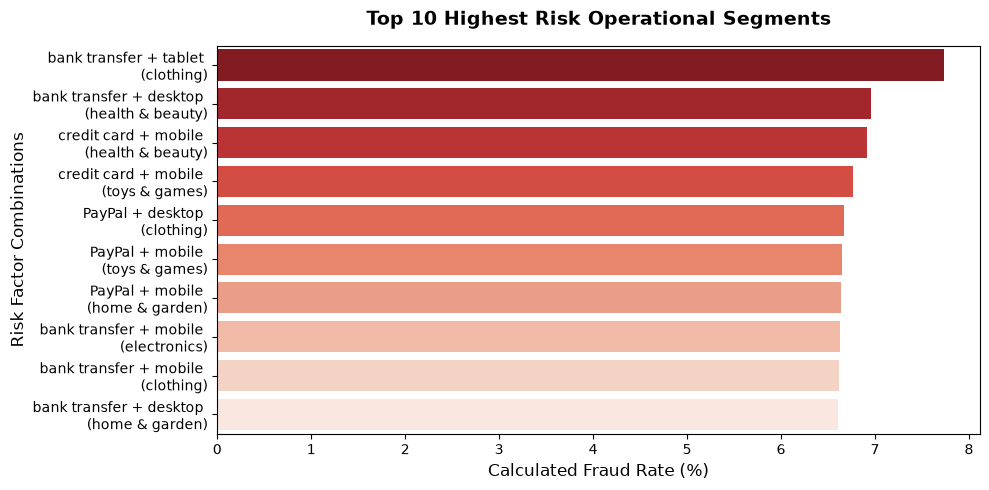

In [19]:
# Convert your top 10 multi-index results into a flat displayable DataFrame
top_combos = fraud_rate.sort_values(ascending=False).head(10).reset_index()
top_combos.columns = ['Payment Method', 'Device Used', 'Product Category', 'Fraud Rate (%)']

plt.figure(figsize=(10, 5))
# Concat values for clear categorical axis tags
y_labels = top_combos['Payment Method'] + ' + ' + top_combos['Device Used'] + ' \n(' + top_combos['Product Category'] + ')'

sns.barplot(data=top_combos, x='Fraud Rate (%)', y=y_labels, palette='Reds_r')
plt.title('Top 10 Highest Risk Operational Segments', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Calculated Fraud Rate (%)', fontsize=12)
plt.ylabel('Risk Factor Combinations', fontsize=12)
plt.tight_layout()
plt.show()

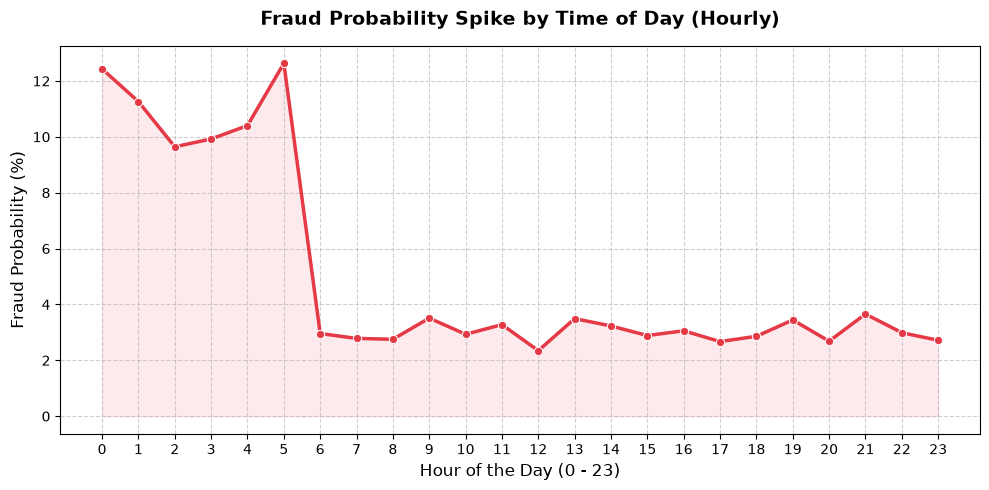

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate dynamic fraud rate percentage per hour
hourly_fraud = df.groupby(['Transaction Hour', 'Is Fraudulent']).size().unstack(fill_value=0)
hourly_fraud_percentage = (hourly_fraud[1] / (hourly_fraud[0] + hourly_fraud[1])) * 100

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_fraud_percentage.index, y=hourly_fraud_percentage.values,
             marker='o', color='#E63946', linewidth=2.5)
plt.fill_between(hourly_fraud_percentage.index, hourly_fraud_percentage.values, color='#E63946', alpha=0.1)

plt.title('Fraud Probability Spike by Time of Day (Hourly)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hour of the Day (0 - 23)', fontsize=12)
plt.ylabel('Fraud Probability (%)', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [21]:
data_col = df['Transaction Amount']

# 2. Let pandas calculate Q1 (25th) and Q3 (75th) percentiles
Q1 = data_col.quantile(0.25)
Q3 = data_col.quantile(0.75)

# 3. Calculate IQR
IQR = Q3 - Q1

# 4. Use the formula to find the boundary
upper_outlier_threshold = Q3 + (1.5 * IQR)

print(f"The exact mathematical outlier threshold is: ${upper_outlier_threshold:.2f}")

The exact mathematical outlier threshold is: $636.71


C:\Users\KTL\AppData\Local\Temp\ipykernel_20136\4102136825.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Is Fraudulent', y='Transaction Amount', data=df,


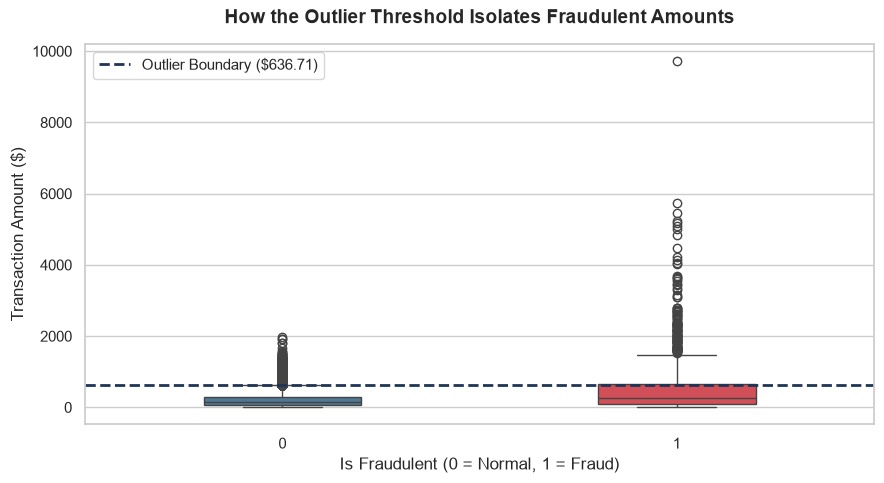

In [22]:
OUTLIER_THRESHOLD = 636.71

# 3. Create the box plot
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# Blue for legitimate transactions, Red for fraud
ax = sns.boxplot(x='Is Fraudulent', y='Transaction Amount', data=df,
                 palette=['#457B9D', '#E63946'], width=0.4)

# 4. Draw a dashed line right across our outlier threshold
plt.axhline(y=OUTLIER_THRESHOLD, color='#1D3557', linestyle='--', linewidth=2,
            label=f'Outlier Boundary (${OUTLIER_THRESHOLD})')

# 5. Make it look professional
plt.title('How the Outlier Threshold Isolates Fraudulent Amounts', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Is Fraudulent (0 = Normal, 1 = Fraud)', fontsize=12)
plt.ylabel('Transaction Amount ($)', fontsize=12)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [23]:
# Clean up shipping and billing address text blocks (remove hidden newlines '\n')
df['Shipping Address'] = df['Shipping Address'].astype(str).str.replace('\n', ', ', regex=False).str.strip()
df['Billing Address'] = df['Billing Address'].astype(str).str.replace('\n', ', ', regex=False).str.strip()

In [24]:
categorical_text_cols = ['Payment Method', 'Product Category', 'Device Used', 'Customer Location']

for col in categorical_text_cols:
    df[col] = df[col].astype(str).str.strip().str.lower()

In [25]:
# Remove impossible logical entries
df = df[df['Transaction Amount'] >= 0]
df = df[df['Quantity'] > 0]
df = df[df['Customer Age'] >= 18]
df = df[df['Account Age Days'] >= 0]

In [26]:
# Fraudsters often use a stolen card billing address but ship to a drop-box address
df['Is_Address_Mismatch'] = (df['Shipping Address'].str.lower().str.strip() !=
                             df['Billing Address'].str.lower().str.strip()).astype(int)

In [27]:
columns_to_drop = [
    'Transaction ID',
    'Customer ID',
    'Transaction Date',
    'IP Address',
    'Shipping Address',
    'Billing Address'
]

df_ml = df.drop(columns=columns_to_drop)

# ============================
# 2. Split Features & Target
# ============================

X = df_ml.drop(columns=['Is Fraudulent'])
y = df_ml['Is Fraudulent']

# Convert target to 0/1 if needed
if y.dtype == 'object':
    y = y.map({'No':0, 'Yes':1})

# ============================
# 3. Define columns
# ============================

low_cardinality_cols = [
    'Payment Method',
    'Product Category',
    'Device Used'
]

high_cardinality_cols = [
    'Customer Location'
]

# Numeric columns
numeric_cols = [
    'Transaction Amount',
    'Quantity',
    'Customer Age',
    'Account Age Days',
    'Transaction Hour',
    'Is_Address_Mismatch'
]

# Convert numeric columns
for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# ============================
# 4. Train Test Split
# ============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ============================
# 5. Preprocessing
# ============================

preprocessor = ColumnTransformer(
    transformers=[
        (
            'onehot',
            OneHotEncoder(drop='first', sparse_output=False),
            low_cardinality_cols
        ),
        (
            'target',
            TargetEncoder(),
            high_cardinality_cols
        )
    ],
    remainder='passthrough'
)

# ============================
# 6. Transform Data
# ============================

X_train_encoded = preprocessor.fit_transform(X_train, y_train)
X_test_encoded = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

X_test_final = pd.DataFrame(
    X_test_encoded,
    columns=feature_names,
    index=X_test.index
)

# Remove prefixes
X_train_final.columns = [c.split("__")[-1] for c in X_train_final.columns]
X_test_final.columns = [c.split("__")[-1] for c in X_test_final.columns]

# ============================
# 7. Convert everything to numeric
# ============================

X_train_final = X_train_final.apply(pd.to_numeric, errors='coerce')
X_test_final = X_test_final.apply(pd.to_numeric, errors='coerce')

# Fill missing values
X_train_final = X_train_final.fillna(0)
X_test_final = X_test_final.fillna(0)

# Convert to float
X_train_final = X_train_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# ============================
# 8. Train XGBoost
# ============================



In [28]:
num_neg = np.sum(y_train == 0)
num_pos = np.sum(y_train == 1)

model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=num_neg / num_pos,
    eval_metric='logloss',
    random_state=42
)

print("Training XGBoost Model...")

model.fit(X_train_final, y_train)



Training XGBoost Model...


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [29]:
y_pred = model.predict(X_test_final)

# Probability predictions
y_prob = model.predict_proba(X_test_final)[:, 1]


In [30]:
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")


Accuracy : 0.8226
Precision: 0.1599
Recall   : 0.5660
F1 Score : 0.2493
ROC AUC  : 0.7762


In [31]:
cm = confusion_matrix(y_test, y_pred)
print(f"True Negatives (Legit caught): {cm[0][0]}")
print(f"False Positives (Legit blocked falsely): {cm[0][1]}")
print(f"False Negatives (Fraud missed!): {cm[1][0]}")
print(f"True Positives (Fraud caught!): {cm[1][1]}")

True Negatives (Legit caught): 3582
False Positives (Legit blocked falsely): 699
False Negatives (Fraud missed!): 102
True Positives (Fraud caught!): 133


In [32]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score
from sklearn.metrics import precision_recall_curve

In [33]:
probabilities=cross_val_predict(model,X_train_final,y_train,cv=5,method='predict_proba')[:,1]

In [34]:
precision, recall, thresholds = precision_recall_curve(y_train,probabilities)

In [35]:
def plot_precesion_recall_vs_threshold(preciosn,recall,thresholds):
  plt.plot(thresholds,preciosn[:-1],"b--",label="Precision")
  plt.plot(thresholds,recall[:-1],"g-",label="Recall")
  plt.xlabel("Threshold")
  plt.legend(loc="upper left")
  plt.ylim([0,1])

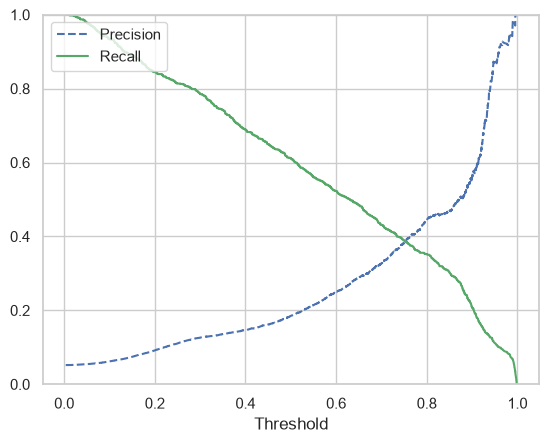

In [36]:
plot_precesion_recall_vs_threshold(precision,recall,thresholds)
plt.show()

In [37]:
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (
    precision[:-1] + recall[:-1] + 1e-10
)

best_idx = np.argmax(f1_scores)

print("Best threshold :", thresholds[best_idx])
print("Precision      :", precision[best_idx])
print("Recall         :", recall[best_idx])
print("F1             :", f1_scores[best_idx])

Best threshold : 0.80563986
Precision      : 0.45254470426409904
Recall         : 0.3503727369542066
F1             : 0.3949579831440869


In [38]:
best_threshold = 0.7812411
y_pred = (y_prob >= best_threshold).astype(int)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.97      0.97      4281
           1       0.38      0.34      0.36       235

    accuracy                           0.94      4516
   macro avg       0.67      0.66      0.66      4516
weighted avg       0.93      0.94      0.93      4516

[[4146  135]
 [ 154   81]]


In [39]:
!pip install optuna


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import make_scorer, fbeta_score

c:\Users\KTL\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [41]:
f2_scorer = make_scorer(fbeta_score, beta=2)

In [42]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [43]:
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

In [44]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10, log=True),
        "scale_pos_weight": num_neg / num_pos,
        "eval_metric": "logloss",
        "random_state": 42,
    }
    model = XGBClassifier(**params)
    score = cross_val_score(
        model,
        X_train_final,
        y_train,
        cv=cv,
        scoring=f2_scorer,
        n_jobs=-1
    ).mean()
    return score

In [45]:
study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=100)

[I 2026-07-16 19:02:58,217] A new study created in memory with name: no-name-96bc592d-df90-4c6a-a527-ed52c5ad608d
[I 2026-07-16 19:03:08,951] Trial 0 finished with value: 0.40100870585524645 and parameters: {'n_estimators': 460, 'max_depth': 10, 'learning_rate': 0.206587987320855, 'min_child_weight': 2, 'subsample': 0.7898387358647035, 'colsample_bytree': 0.9838159184871069, 'gamma': 4.745672082543349, 'reg_alpha': 1.013647534628087, 'reg_lambda': 0.2669921257112232}. Best is trial 0 with value: 0.40100870585524645.
[I 2026-07-16 19:03:13,546] Trial 1 finished with value: 0.42144516885230987 and parameters: {'n_estimators': 362, 'max_depth': 5, 'learning_rate': 0.12004657096489124, 'min_child_weight': 8, 'subsample': 0.9601010030565685, 'colsample_bytree': 0.8012626763707251, 'gamma': 1.3556504244035712, 'reg_alpha': 1.5135424432232019, 'reg_lambda': 1.2227065308286005}. Best is trial 1 with value: 0.42144516885230987.
[I 2026-07-16 19:03:17,646] Trial 2 finished with value: 0.41212359

In [46]:
print(study.best_params)
print(study.best_value)

{'n_estimators': 219, 'max_depth': 10, 'learning_rate': 0.01306890295610332, 'min_child_weight': 10, 'subsample': 0.657056350163261, 'colsample_bytree': 0.6387538856377757, 'gamma': 1.5120926753635797, 'reg_alpha': 4.70013649483804, 'reg_lambda': 3.8037354148189513}
0.45299180062951355


In [47]:
#{'n_estimators': 369, 'max_depth': 9, 'learning_rate': 0.010998527406947895, 'min_child_weight': 10, 'subsample': 0.8535878930581122, 'colsample_bytree': 0.674430317332468, 'gamma': 0.8662347378771535, 'reg_alpha': 4.651581059654922, 'reg_lambda': 2.5719768623024257}
#0.44799014732822534
best_model = XGBClassifier(
    **study.best_params,
    scale_pos_weight=num_neg/num_pos,
    eval_metric="logloss",
    random_state=42
)

best_model.fit(X_train_final, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.6387538856377757
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [48]:
y_pred = best_model.predict(X_test_final)
y_prob = best_model.predict_proba(X_test_final)[:,1]

In [49]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8660318866253321
Precision: 0.20352564102564102
Recall   : 0.5404255319148936
F1 Score : 0.2956926658905704
ROC AUC  : 0.7937159243962686


In [50]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.88      0.93      4281
           1       0.20      0.54      0.30       235

    accuracy                           0.87      4516
   macro avg       0.59      0.71      0.61      4516
weighted avg       0.93      0.87      0.89      4516

[[3784  497]
 [ 108  127]]


In [51]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_final, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [52]:
y_pred_rf = rf_model.predict(X_test_final)
y_prob_rf = rf_model.predict_proba(X_test_final)[:,1]

In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_rf))

Random Forest Results
---------------------
Accuracy : 0.9189548272807795
Precision: 0.29846153846153844
Recall   : 0.4127659574468085
F1 Score : 0.3464285714285714
ROC AUC  : 0.7899426958306618


In [54]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

print("="*70)
print(f"{'Threshold':<10}{'Accuracy':<12}{'Precision':<12}{'Recall':<12}{'F1 Score'}")
print("="*70)

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"{threshold:<10}{acc:.4f}      {prec:.4f}      {rec:.4f}      {f1:.4f}")

Threshold Accuracy    Precision   Recall      F1 Score
0.2       0.4794      0.0815      0.8766      0.1491
0.3       0.6940      0.1189      0.7617      0.2057
0.4       0.7921      0.1542      0.6681      0.2506
0.5       0.8660      0.2035      0.5404      0.2957
0.6       0.9150      0.2936      0.4511      0.3557


In [55]:
best_threshold = 0.30

y_pred = (y_prob >= best_threshold).astype(int)

In [56]:
print(classification_report(y_test, y_pred))

print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("ROC AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.98      0.69      0.81      4281
           1       0.12      0.76      0.21       235

    accuracy                           0.69      4516
   macro avg       0.55      0.73      0.51      4516
weighted avg       0.94      0.69      0.78      4516

Confusion Matrix
[[2955 1326]
 [  56  179]]
ROC AUC: 0.7937159243962686


In [57]:
#optuna tuning on random forest
def objective2(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 5, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical(
            "max_features",
            ["sqrt", "log2", None]
        ),
        "bootstrap": trial.suggest_categorical(
            "bootstrap",
            [True, False]
        ),
        "class_weight": "balanced",
        "random_state": 42,
        "n_jobs": -1
    }
    model = RandomForestClassifier(**params)
    score = cross_val_score(
        model,
        X_train_final,
        y_train,
        cv=cv,
        scoring=f2_scorer,
        n_jobs=-1
    ).mean()
    return score

In [58]:
study_rf = optuna.create_study(direction="maximize")

study_rf.optimize(objective2, n_trials=50)

print(study_rf.best_params)
print(study_rf.best_value)

[I 2026-07-16 19:07:58,570] A new study created in memory with name: no-name-d88cd9a2-10f7-499f-9969-b3b71b9dbee3
[I 2026-07-16 19:08:04,796] Trial 0 finished with value: 0.43838215339133163 and parameters: {'n_estimators': 163, 'max_depth': 13, 'min_samples_split': 9, 'min_samples_leaf': 1, 'max_features': 'log2', 'bootstrap': True}. Best is trial 0 with value: 0.43838215339133163.
[I 2026-07-16 19:08:22,995] Trial 1 finished with value: 0.4319377071263501 and parameters: {'n_estimators': 407, 'max_depth': 15, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 'log2', 'bootstrap': False}. Best is trial 0 with value: 0.43838215339133163.
[I 2026-07-16 19:08:31,333] Trial 2 finished with value: 0.42338001578814755 and parameters: {'n_estimators': 207, 'max_depth': 14, 'min_samples_split': 15, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'bootstrap': False}. Best is trial 0 with value: 0.43838215339133163.
[I 2026-07-16 19:08:52,697] Trial 3 finished with value: 0.41857849

{'n_estimators': 460, 'max_depth': 30, 'min_samples_split': 5, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'bootstrap': True}
0.4502837630227668


In [59]:
best_rf = XGBClassifier(
    **study.best_params,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train_final, y_train)

c:\Users\KTL\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [19:26:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.6387538856377757
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [60]:
y_pred = best_rf.predict(X_test_final)
y_prob = best_rf.predict_proba(X_test_final)[:, 1]

In [61]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.9515057573073517
Precision: 0.8636363636363636
Recall   : 0.08085106382978724
F1 Score : 0.14785992217898833
ROC AUC  : 0.8057632189734949


In [62]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.98      4281
           1       0.86      0.08      0.15       235

    accuracy                           0.95      4516
   macro avg       0.91      0.54      0.56      4516
weighted avg       0.95      0.95      0.93      4516

[[4278    3]
 [ 216   19]]


In [63]:
import joblib

joblib.dump(best_model, "xgboost_optuna.pkl")

['xgboost_optuna.pkl']

In [64]:
joblib.dump(best_rf, "random_forest_optuna.pkl")

['random_forest_optuna.pkl']

In [65]:
best_xgb = XGBClassifier(
    n_estimators=369,
    max_depth=9,
    learning_rate=0.010998527406947895,
    min_child_weight=10,
    subsample=0.8535878930581122,
    colsample_bytree=0.674430317332468,
    gamma=0.8662347378771535,
    reg_alpha=4.651581059654922,
    reg_lambda=2.5719768623024257,
    scale_pos_weight=num_neg/num_pos,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(X_train_final, y_train)

y_pred = best_xgb.predict(X_test_final)
y_prob = best_xgb.predict_proba(X_test_final)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix")
print(cm)

print(f"\nTrue Negatives : {cm[0][0]}")
print(f"False Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]}")
print(f"True Positives : {cm[1][1]}")

Accuracy : 0.8689
Precision: 0.2088
Recall   : 0.5447
F1 Score : 0.3019
ROC AUC  : 0.7842

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.89      0.93      4281
           1       0.21      0.54      0.30       235

    accuracy                           0.87      4516
   macro avg       0.59      0.72      0.61      4516
weighted avg       0.93      0.87      0.90      4516


Confusion Matrix
[[3796  485]
 [ 107  128]]

True Negatives : 3796
False Positives: 485
False Negatives: 107
True Positives : 128


In [66]:
model = joblib.load("xgboost_optuna.pkl")
params = model.get_params()

keys = [
    "n_estimators",
    "max_depth",
    "learning_rate",
    "min_child_weight",
    "subsample",
    "colsample_bytree",
    "gamma",
    "reg_alpha",
    "reg_lambda",
    "scale_pos_weight"
]

for k in keys:
    print(f"{k}: {params[k]}")

n_estimators: 219
max_depth: 10
learning_rate: 0.01306890295610332
min_child_weight: 10
subsample: 0.657056350163261
colsample_bytree: 0.6387538856377757
gamma: 1.5120926753635797
reg_alpha: 4.70013649483804
reg_lambda: 3.8037354148189513
scale_pos_weight: 18.23748668796592


In [67]:
joblib.dump(preprocessor, "preprocessor.pkl")

['preprocessor.pkl']

In [68]:
print(df["Payment Method"].unique())

print(df["Product Category"].unique())

print(df["Device Used"].unique())

<ArrowStringArray>
['paypal', 'credit card', 'debit card', 'bank transfer']
Length: 4, dtype: str
<ArrowStringArray>
['electronics', 'toys & games', 'clothing', 'home & garden',
 'health & beauty']
Length: 5, dtype: str
<ArrowStringArray>
['desktop', 'tablet', 'mobile']
Length: 3, dtype: str


In [69]:
feature_names = preprocessor.get_feature_names_out()

import pandas as pd

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(20))

                                     Feature  Importance
13               remainder__Account Age Days    0.313568
10             remainder__Transaction Amount    0.238664
14               remainder__Transaction Hour    0.188200
12                   remainder__Customer Age    0.085977
11                       remainder__Quantity    0.037330
9                  target__Customer Location    0.033137
7                 onehot__Device Used_mobile    0.012059
2              onehot__Payment Method_paypal    0.011847
0         onehot__Payment Method_credit card    0.011084
8                 onehot__Device Used_tablet    0.010756
1          onehot__Payment Method_debit card    0.010539
5     onehot__Product Category_home & garden    0.010244
4   onehot__Product Category_health & beauty    0.009794
6      onehot__Product Category_toys & games    0.009507
3       onehot__Product Category_electronics    0.009009
15            remainder__Is_Address_Mismatch    0.008285


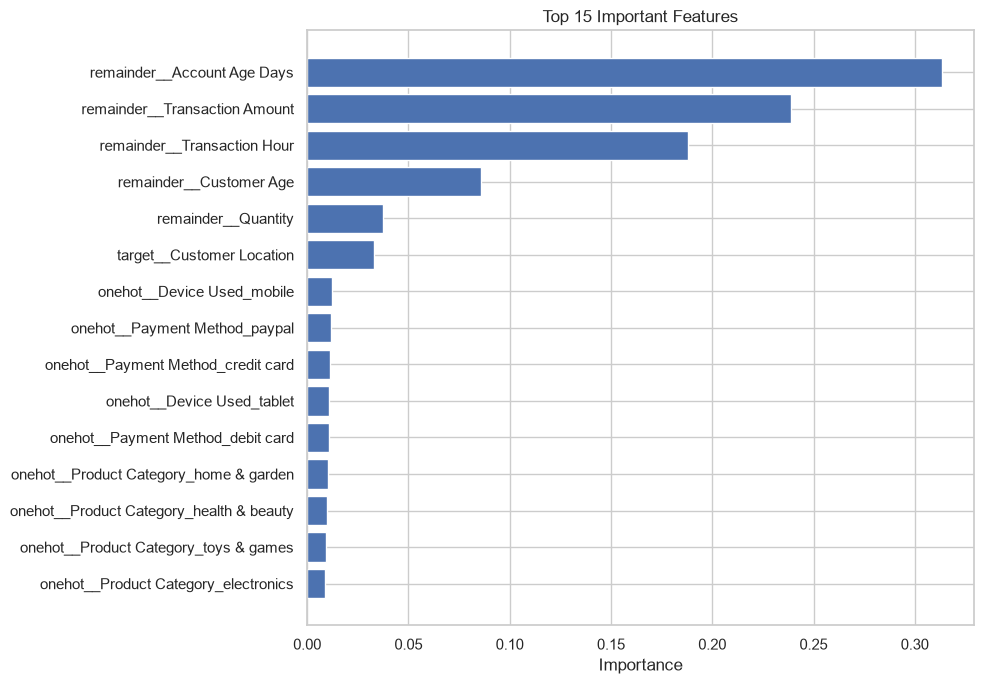

In [70]:
import matplotlib.pyplot as plt

top = importance.head(15)

plt.figure(figsize=(10,7))
plt.barh(top["Feature"], top["Importance"])
plt.gca().invert_yaxis()
plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()